# Лабораторная работа №1. Метод обратного распространения ошибки

**Цель:** изучить и реализовать обучение двухслойной полносвязной нейронной сети методом обратного распространения ошибки и мини-пакетного стохастического градиентного спуска на MNIST.

**Автор и группа:** Сычёв Егор Андреевич, 3825сФИ1.

Используются NumPy и Matplotlib, без фреймворков глубокого обучения и автоматического дифференцирования. Контрольная конфигурация: **784 → 300 (ReLU) → 10 (softmax)**, learning rate **0.1**, batch size **64**, **20 эпох**. Тестовая выборка не участвует в обновлении весов или выборе параметров.

Для повторного запуска установите зависимости из `requirements.txt` и выполните **Kernel → Restart Kernel and Run All Cells**. Первый запуск скачивает MNIST (около 11 МБ); последующие используют `data/mnist.npz`. При отсутствии интернета заранее сохраните этот файл рядом с ноутбуком в папке `data`. HTML получен стандартным Jupyter nbconvert из выполненного ноутбука.

## 1. Прямое распространение и функция потерь

Объекты располагаются по строкам. Для пачки из $m$ примеров:

| Величина | Размерность | Смысл |
|---|---|---|
| $X$ | $m\times784$ | Нормированные изображения |
| $Y$ | $m\times10$ | One-hot метки |
| $W_1,b_1$ | $784\times s$, $s$ | Параметры скрытого слоя |
| $W_2,b_2$ | $s\times10$, $10$ | Параметры выходного слоя |

$$Z_1=XW_1+b_1,\qquad H=\max(0,Z_1),\qquad Z_2=HW_2+b_2.$$

Смещения прибавляются к каждой строке. Вероятность класса:
$$P_{ij}=\frac{\exp(Z_{2,ij})}{\sum_{k=1}^{10}\exp(Z_{2,ik})}.$$

Используется обычная прямая формула softmax без вычитания максимума. Кросс-энтропия усредняется по пачке:
$$L=-\frac1m\sum_i\sum_jY_{ij}\log P_{ij}.$$

В коде логарифм вычисляется непосредственно от вероятностей softmax. Целочисленная метка эквивалентна one-hot представлению при выборе вероятности правильного класса. Предсказание: $\hat y_i=\arg\max_jP_{ij}$.

## 2. Вывод градиентов и правило коррекции весов

Для одного примера $\partial P_j/\partial z_k=P_j(\delta_{jk}-P_k)$, а $\partial\ell/\partial P_j=-Y_j/P_j$. Поэтому
$$\frac{\partial\ell}{\partial z_k}
=-\sum_jY_j(\delta_{jk}-P_k)=P_k-Y_k,$$
поскольку $\sum_jY_j=1$. С учётом усреднения:
$$D_2=\frac{\partial L}{\partial Z_2}=\frac{P-Y}{m},\qquad
\nabla_{W_2}L=H^TD_2,\qquad \nabla_{b_2}L=\sum_iD_{2,i:}.$$

По цепному правилу через скрытый слой:
$$D_1=(D_2W_2^T)\odot\mathbf1[Z_1>0],\qquad
\nabla_{W_1}L=X^TD_1,\qquad \nabla_{b_1}L=\sum_iD_{1,i:}.$$

В нуле выбираем производную ReLU равной нулю. Все градиенты вычисляются **до изменения весов**, иначе в $D_1$ попали бы уже обновлённые параметры. Для каждого $\theta\in\{W_1,b_1,W_2,b_2\}$:
$$\theta\leftarrow\theta-\eta\nabla_\theta L.$$

В начале эпохи обучающие объекты перемешиваются, затем обрабатываются пачками без возвращения. Последняя пачка может быть меньше; деление производится на её фактический размер. Это мини-пакетный SGD без momentum и адаптивных оптимизаторов.

Первый слой инициализируем по He: $W_{1,ij}\sim\mathcal N(0,2/784)$, чтобы компенсировать подавление части сигналов ReLU. Для линейных выходных логитов используем $W_{2,ij}\sim\mathcal N(0,1/s)$, смещения нулевые. Случайные веса нарушают симметрию нейронов; нулевые веса не подходят. Все генераторы имеют фиксированные seed.

In [1]:
import os
os.environ['OPENBLAS_NUM_THREADS'] = '2'
os.environ['OMP_NUM_THREADS'] = '2'
from pathlib import Path
from urllib.request import urlretrieve
from time import perf_counter
import sys
import platform
import numpy as np
import matplotlib.pyplot as plt
from threadpoolctl import threadpool_limits, threadpool_info
from IPython.display import display, Markdown

# Ограничение потоков уменьшает накладные расходы на маленьких матрицах.
blas_limit = threadpool_limits(limits=2, user_api='blas')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': False})
print('Python:', sys.version.split()[0], '| NumPy:', np.__version__)
print('Система:', platform.platform())
print('BLAS:', [(x['internal_api'], x['num_threads']) for x in threadpool_info()])

Python: 3.11.18 | NumPy: 2.4.6
Система: Windows-10-10.0.26200-SP0
BLAS: [('openblas', 2)]


## 3. Загрузка и подготовка MNIST

Используется стандартное разбиение MNIST: 60 000 обучающих и 10 000 тестовых изображений 28×28. [MNIST из задания](https://www.kaggle.com/datasets/hojjatk/mnist-dataset) загружается в удобной NPZ-упаковке из [публичного зеркала](https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz). Название пути зеркала не означает использование TensorFlow: файл читается исключительно NumPy.

Пиксели переводятся из uint8 [0,255] в float32 [0,1], изображения разворачиваются в векторы длины 784. Дополнительного центрирования, аугментаций и подбора гиперпараметров нет. Метки остаются целыми числами 0–9.

Train: N=60000, изображения=(60000, 28, 28), изображение=(28, 28)
  X=(60000, 784), dtype=float32, диапазон=[0.0, 1.0]
  y=(60000,), dtype=int64, одна метка: shape=(); one-hot: (60000, 10)
Test: N=10000, изображения=(10000, 28, 28), изображение=(28, 28)
  X=(10000, 784), dtype=float32, диапазон=[0.0, 1.0]
  y=(10000,), dtype=int64, одна метка: shape=(); one-hot: (10000, 10)


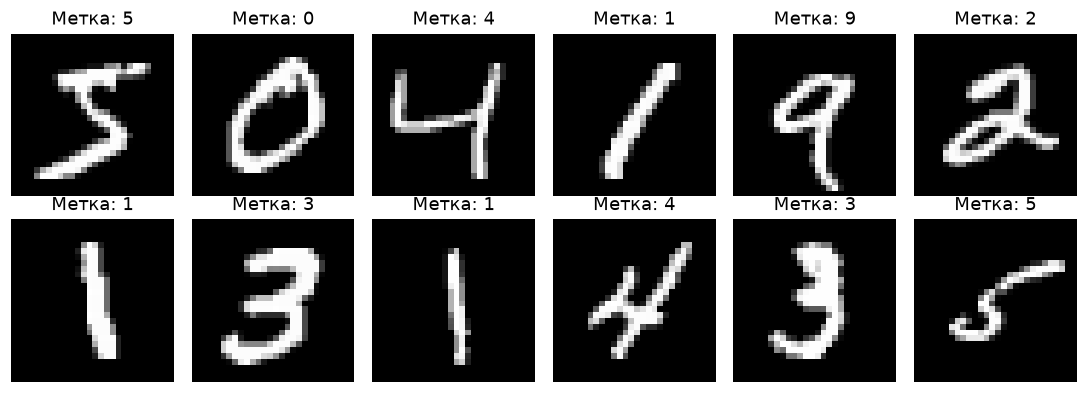

In [2]:
data_path = Path('data/mnist.npz')
data_path.parent.mkdir(exist_ok=True)
if not data_path.exists():
    url = 'https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz'
    temporary = data_path.with_suffix('.tmp')
    urlretrieve(url, temporary)
    temporary.replace(data_path)
with np.load(data_path, allow_pickle=False) as data:
    train_images, y_train = data['x_train'], data['y_train'].astype(np.int64)
    test_images, y_test = data['x_test'], data['y_test'].astype(np.int64)
assert train_images.shape == (60000, 28, 28)
assert test_images.shape == (10000, 28, 28)
assert set(np.unique(y_train)) == set(range(10))
assert set(np.unique(y_test)) == set(range(10))
X_train = train_images.reshape(-1, 784).astype(np.float32) / 255.0
X_test = test_images.reshape(-1, 784).astype(np.float32) / 255.0
for name, images, X, y in [('Train', train_images, X_train, y_train),
                          ('Test', test_images, X_test, y_test)]:
    print(f'{name}: N={len(X)}, изображения={images.shape}, изображение={images[0].shape}')
    print(f'  X={X.shape}, dtype={X.dtype}, диапазон=[{X.min()}, {X.max()}]')
    print(f'  y={y.shape}, dtype={y.dtype}, одна метка: shape={y[0].shape}; one-hot: ({len(y)}, 10)')
fig, axes = plt.subplots(2, 6, figsize=(10, 3.6))
for ax, i in zip(axes.flat, range(12)):
    ax.imshow(train_images[i], cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'Метка: {y_train[i]}')
    ax.axis('off')
fig.tight_layout()
plt.show()

## 4. Реализация прямого и обратного распространения на NumPy

In [3]:
def initialize(input_dim=784, hidden_dim=300, classes=10, seed=42, dtype=np.float32):
    rng = np.random.default_rng(seed)
    return {
        'W1': (rng.standard_normal((input_dim, hidden_dim)) * np.sqrt(2 / input_dim)).astype(dtype),
        'b1': np.zeros(hidden_dim, dtype=dtype),
        'W2': (rng.standard_normal((hidden_dim, classes)) / np.sqrt(hidden_dim)).astype(dtype),
        'b2': np.zeros(classes, dtype=dtype),
    }

def forward(X, params):
    Z1 = X @ params['W1'] + params['b1']
    H = np.maximum(Z1, 0)
    logits = H @ params['W2'] + params['b2']
    exp_logits = np.exp(logits)
    sums = exp_logits.sum(axis=1, keepdims=True)
    P = exp_logits / sums
    log_P = np.log(P)
    return P, log_P, (X, Z1, H)

def loss_and_gradients(X, y, params):
    P, log_P, (_, Z1, H) = forward(X, params)
    m = len(X)
    loss = -log_P[np.arange(m), y].mean()
    D2 = P.copy()
    D2[np.arange(m), y] -= 1
    D2 /= m
    D1 = (D2 @ params['W2'].T) * (Z1 > 0)
    grads = {'W1': X.T @ D1, 'b1': D1.sum(axis=0),
             'W2': H.T @ D2, 'b2': D2.sum(axis=0)}
    return float(loss), grads

def evaluate(X, y, params, batch_size=1024):
    total_loss, wrong = 0.0, 0
    predictions = np.empty(len(y), dtype=np.int64)
    for start in range(0, len(X), batch_size):
        stop = min(start + batch_size, len(X))
        P, log_P, _ = forward(X[start:stop], params)
        pred = P.argmax(axis=1)
        predictions[start:stop] = pred
        total_loss += float(-log_P[np.arange(stop-start), y[start:stop]].sum())
        wrong += int(np.count_nonzero(pred != y[start:stop]))
    return total_loss / len(X), wrong / len(X), predictions

## 5. Проверка реализации

До обучения проверим все компоненты градиента небольшой сети центральными конечными разностями:
$$g_j^{num}=\frac{L(\theta+\varepsilon e_j)-L(\theta-\varepsilon e_j)}{2\varepsilon}.$$
Используем float64 и $\varepsilon=10^{-5}$, а также проверим, что точки ReLU достаточно удалены от нуля. Нормированное расхождение $\|g^{num}-g\|_2/(\|g^{num}\|_2+\|g\|_2)$ должно быть меньше $10^{-6}$. Дополнительно проверяется нормировка softmax и уменьшение функции потерь после малого шага SGD.

In [4]:
check_rng = np.random.default_rng(7)
check_X = check_rng.normal(size=(5, 4))
check_y = np.array([0, 1, 2, 1, 0])
check_params = initialize(4, 6, 3, seed=8, dtype=np.float64)
eps = 1e-5
assert np.min(np.abs(forward(check_X, check_params)[2][1])) > 1e-3
base_loss, analytical = loss_and_gradients(check_X, check_y, check_params)
for name, parameter in check_params.items():
    numerical = np.zeros_like(parameter)
    for index in np.ndindex(parameter.shape):
        original = parameter[index]
        parameter[index] = original + eps
        plus = loss_and_gradients(check_X, check_y, check_params)[0]
        parameter[index] = original - eps
        minus = loss_and_gradients(check_X, check_y, check_params)[0]
        parameter[index] = original
        numerical[index] = (plus - minus) / (2 * eps)
    error = np.linalg.norm(numerical - analytical[name]) / max(
        1e-12, np.linalg.norm(numerical) + np.linalg.norm(analytical[name]))
    print(f'{name}: относительное расхождение {error:.3e}')
    assert error < 1e-6
P = forward(check_X, check_params)[0]
assert np.allclose(P.sum(axis=1), 1) and np.all(P >= 0)
updated = {k: v - 1e-3 * analytical[k] for k, v in check_params.items()}
new_loss = loss_and_gradients(check_X, check_y, updated)[0]
assert new_loss < base_loss
print(f'Малый шаг SGD: {base_loss:.6f} → {new_loss:.6f}')
print('Все проверки пройдены.')

W1: относительное расхождение 3.413e-11
b1: относительное расхождение 2.111e-11
W2: относительное расхождение 4.162e-11
b2: относительное расхождение 5.425e-12
Малый шаг SGD: 0.635466 → 0.635182
Все проверки пройдены.


## 6. Обучение: контрольные параметры

После каждой эпохи вычисляем кросс-энтропию и ошибку классификации **на всей обучающей выборке с итоговыми весами данной эпохи**. Ошибка классификации — доля неверных ответов, а не кросс-энтропия. Время эпохи включает обновления весов и эту оценку. Тестовую выборку оцениваем только после завершения обучения.

In [5]:
HIDDEN_SIZE, LEARNING_RATE, BATCH_SIZE, EPOCHS = 300, 0.1, 64, 20
params = initialize(hidden_dim=HIDDEN_SIZE, seed=42)
shuffle_rng = np.random.default_rng(43)
history = []
training_start = perf_counter()
for epoch in range(1, EPOCHS + 1):
    epoch_start = perf_counter()
    order = shuffle_rng.permutation(len(X_train))
    for start in range(0, len(order), BATCH_SIZE):
        indices = order[start:start + BATCH_SIZE]
        loss, grads = loss_and_gradients(X_train[indices], y_train[indices], params)
        for name in params:
            params[name] -= LEARNING_RATE * grads[name]
    train_loss, train_error, _ = evaluate(X_train, y_train, params)
    seconds = perf_counter() - epoch_start
    history.append((epoch, train_loss, train_error, seconds))
    print(f'Эпоха {epoch:2d}/{EPOCHS}: CE={train_loss:.5f}, '
          f'ошибка={train_error:.2%}, точность={1-train_error:.2%}, время={seconds:.2f} с', flush=True)
training_seconds = perf_counter() - training_start
print(f'Всего обучение с оценкой train: {training_seconds:.2f} с ({training_seconds / 60:.2f} мин)')
assert np.isfinite(np.array(history)).all()

Эпоха  1/20: CE=0.23076, ошибка=6.46%, точность=93.53%, время=0.42 с
Эпоха  2/20: CE=0.15809, ошибка=4.41%, точность=95.59%, время=0.37 с
Эпоха  3/20: CE=0.12286, ошибка=3.44%, точность=96.56%, время=0.40 с
Эпоха  4/20: CE=0.09868, ошибка=2.76%, точность=97.24%, время=0.40 с
Эпоха  5/20: CE=0.08326, ошибка=2.29%, точность=97.71%, время=0.37 с
Эпоха  6/20: CE=0.07237, ошибка=2.00%, точность=98.00%, время=0.47 с
Эпоха  7/20: CE=0.06022, ошибка=1.58%, точность=98.41%, время=0.37 с
Эпоха  8/20: CE=0.06783, ошибка=1.96%, точность=98.05%, время=0.39 с
Эпоха  9/20: CE=0.04771, ошибка=1.20%, точность=98.80%, время=0.38 с
Эпоха 10/20: CE=0.04348, ошибка=1.10%, точность=98.90%, время=0.37 с
Эпоха 11/20: CE=0.03887, ошибка=0.94%, точность=99.06%, время=0.37 с
Эпоха 12/20: CE=0.03462, ошибка=0.83%, точность=99.17%, время=0.37 с
Эпоха 13/20: CE=0.03153, ошибка=0.73%, точность=99.27%, время=0.37 с
Эпоха 14/20: CE=0.02878, ошибка=0.61%, точность=99.39%, время=0.38 с
Эпоха 15/20: CE=0.02649, ошибка=0.

## 7. Итоговая оценка и визуализация

Тест: 10000 изображений
Кросс-энтропия: 0.06323
Ошибок: 190; ошибка классификации: 1.90%
Точность: 98.10%
Точность выше 95%: True
Время обучения меньше 7 минут: True


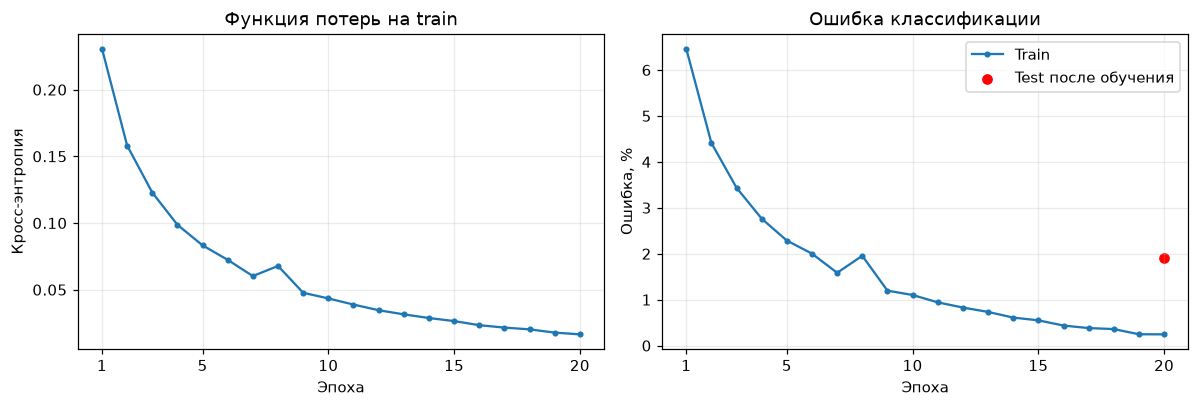

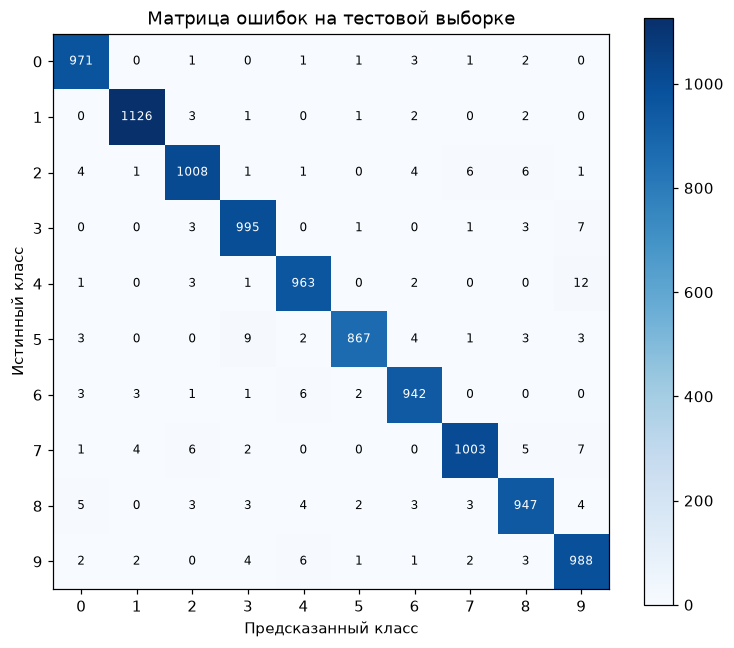

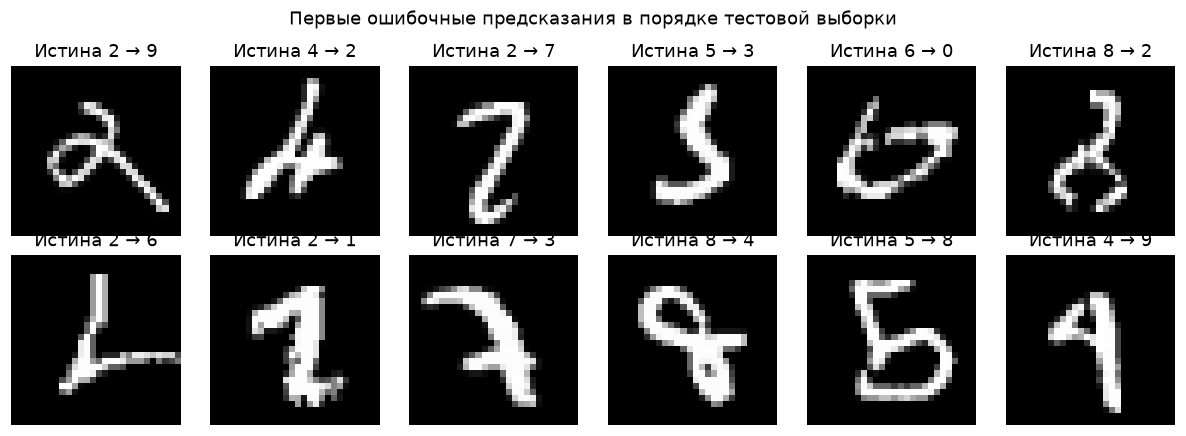

In [6]:
test_loss, test_error, test_predictions = evaluate(X_test, y_test, params)
test_accuracy = 1 - test_error
print(f'Тест: {len(y_test)} изображений')
print(f'Кросс-энтропия: {test_loss:.5f}')
print(f'Ошибок: {np.count_nonzero(test_predictions != y_test)}; ошибка классификации: {test_error:.2%}')
print(f'Точность: {test_accuracy:.2%}')
print('Точность выше 95%:', test_accuracy > 0.95)
print('Время обучения меньше 7 минут:', training_seconds < 420)

h = np.array(history)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(h[:, 0], h[:, 1], marker='o', markersize=3)
axes[0].set(xlabel='Эпоха', ylabel='Кросс-энтропия', title='Функция потерь на train')
axes[1].plot(h[:, 0], h[:, 2] * 100, marker='o', markersize=3, label='Train')
axes[1].scatter([EPOCHS], [test_error * 100], color='red', label='Test после обучения')
axes[1].set(xlabel='Эпоха', ylabel='Ошибка, %', title='Ошибка классификации')
for ax in axes:
    ax.grid(alpha=0.25)
    ax.set_xticks([1, 5, 10, 15, 20])
axes[1].legend()
fig.tight_layout()
plt.show()

confusion = np.zeros((10, 10), dtype=np.int64)
np.add.at(confusion, (y_test, test_predictions), 1)
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(confusion, cmap='Blues')
for i in range(10):
    for j in range(10):
        ax.text(j, i, str(confusion[i, j]), ha='center', va='center', fontsize=8,
                color='white' if confusion[i, j] > confusion.max() / 2 else 'black')
ax.set(xticks=range(10), yticks=range(10), xlabel='Предсказанный класс',
       ylabel='Истинный класс', title='Матрица ошибок на тестовой выборке')
fig.colorbar(im, ax=ax)
fig.tight_layout()
plt.show()

mistakes = np.flatnonzero(test_predictions != y_test)
fig, axes = plt.subplots(2, 6, figsize=(11, 4))
for ax, idx in zip(axes.flat, mistakes[:12]):
    ax.imshow(test_images[idx], cmap='gray')
    ax.set_title(f'Истина {y_test[idx]} → {test_predictions[idx]}')
for ax in axes.flat:
    ax.axis('off')
fig.suptitle('Первые ошибочные предсказания в порядке тестовой выборки')
fig.tight_layout()
plt.show()

In [7]:
off_diagonal = confusion.copy()
np.fill_diagonal(off_diagonal, 0)
true_class, predicted_class = np.unravel_index(off_diagonal.argmax(), off_diagonal.shape)
display(Markdown(f"""
## 8. Выводы

1. Реализована сеть 784 → 300 → 10 с ReLU и softmax. Градиенты получены аналитически и проверены конечными разностями для всех параметров небольшой сети.
2. При mini-batch SGD с learning rate 0.1, batch size 64 и 20 эпохами точность на 10 000 тестовых изображений составила **{test_accuracy:.2%}**, ошибка — **{test_error:.2%}**, кросс-энтропия — **{test_loss:.5f}**. Результат {'превышает' if test_accuracy > 0.95 else 'не превышает'} указанный в задании ориентир 95%.
3. Ошибка на обучающей выборке уменьшилась с **{history[0][2]:.2%}** после первой эпохи до **{history[-1][2]:.2%}** после последней. Разница с тестовой ошибкой показывает, что качество на обучающих объектах не заменяет оценку обобщения.
4. Обучение вместе с оценкой train заняло **{training_seconds:.1f} с ({training_seconds / 60:.2f} мин)** на данной машине. Время зависит от процессора и BLAS; скачивание данных и построение графиков в него не входят.
5. Наиболее частая направленная путаница: истинный класс **{true_class}**, предсказанный **{predicted_class}** — **{off_diagonal[true_class, predicted_class]}** случаев. Примеры ошибок позволяют исследовать неоднозначность начертания цифр.

Использованы обычная прямая формула softmax, кросс-энтропия, подходящая для ReLU инициализация и векторные операции. Тестовые метки использованы только для финальной оценки. Прямое экспериментальное сравнение с Keras/PyTorch не проводилось, поскольку реализация по условию выполняется без этих фреймворков; измеренная точность приводится как самостоятельный воспроизводимый результат.
"""))


## 8. Выводы

1. Реализована сеть 784 → 300 → 10 с ReLU и softmax. Градиенты получены аналитически и проверены конечными разностями для всех параметров небольшой сети.
2. При mini-batch SGD с learning rate 0.1, batch size 64 и 20 эпохами точность на 10 000 тестовых изображений составила **98.10%**, ошибка — **1.90%**, кросс-энтропия — **0.06323**. Результат превышает указанный в задании ориентир 95%.
3. Ошибка на обучающей выборке уменьшилась с **6.46%** после первой эпохи до **0.24%** после последней. Разница с тестовой ошибкой показывает, что качество на обучающих объектах не заменяет оценку обобщения.
4. Обучение вместе с оценкой train заняло **7.9 с (0.13 мин)** на данной машине. Время зависит от процессора и BLAS; скачивание данных и построение графиков в него не входят.
5. Наиболее частая направленная путаница: истинный класс **4**, предсказанный **9** — **12** случаев. Примеры ошибок позволяют исследовать неоднозначность начертания цифр.

Использованы обычная прямая формула softmax, кросс-энтропия, подходящая для ReLU инициализация и векторные операции. Тестовые метки использованы только для финальной оценки. Прямое экспериментальное сравнение с Keras/PyTorch не проводилось, поскольку реализация по условию выполняется без этих фреймворков; измеренная точность приводится как самостоятельный воспроизводимый результат.
